# Ruta Alpes — Laboratorio de clasificación de cupones

**Actividades 1 a 8 y 10.** Trabajamos con `Lab3_Datos.xlsx` y `Lab3_datos_Prueba.xlsx`, en español. Mantenemos separado el problema de Cafetería y Restaurante(<20). La actividad 9 (video) se excluye de acuerdo con la decisión tomada anteriormente.

Nuestro propósito es justificar la preparación de los datos, comparar tres familias de clasificadores y generar predicciones para los registros sin etiqueta. Reservamos un conjunto de prueba para la evaluación final, mientras que la selección de hiperparámetros se realiza únicamente con entrenamiento.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.base import clone

SEMILLA = 42
RUTA_DATOS = Path('Lab3_Datos.xlsx')
RUTA_PRUEBA = Path('Lab3_datos_Prueba.xlsx')
RUTA_SALIDA = Path('Lab3_datos_Prueba_predicciones.csv')
for ruta in [RUTA_DATOS, RUTA_PRUEBA]:
    if not ruta.is_file():
        raise FileNotFoundError(f'No encontramos {ruta}. Coloca ambos Excel junto al notebook.')
datos = pd.read_excel(RUTA_DATOS)
prueba = pd.read_excel(RUTA_PRUEBA)
CUPONES = {'Cafetería':'Cafetería', 'Restaurante(<20)':'Restaurante(<20)'}
assert 'acepta_cupon' in datos and 'cupon' in datos
assert 'acepta_cupon' not in prueba and 'cupon' in prueba
print('Entrenamiento:',datos.shape,'| Archivo sin etiqueta:',prueba.shape)


Entrenamiento: (12664, 26) | Archivo sin etiqueta: (20, 25)


## 1. Exploración y diagnóstico

Primero comprobamos cuántos registros corresponden a cada tipo de cupón, cómo se distribuye la respuesta y qué problemas de calidad requieren una decisión. La proporción de aceptación importa porque una exactitud elevada puede resultar engañosa si una clase predomina.

,Cupón,Registros,Acepta,Rechaza,% acepta,Duplicados exactos,Nulos vehículo
0,Cafetería,3986,1989,1997,49.90,7,3949
1,Restaurante(<20),2776,1962,814,70.68,7,2751


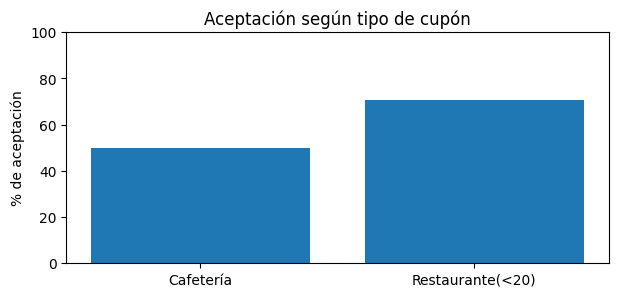

In [2]:
subconjuntos = {nombre: datos.loc[datos['cupon'].eq(valor)].copy() for nombre, valor in CUPONES.items()}
resumen = []
for nombre, tabla in subconjuntos.items():
    res = tabla['acepta_cupon'].value_counts(dropna=False)
    resumen.append({'Cupón':nombre, 'Registros':len(tabla),
                    'Acepta':int(res.get('Sí',0)), 'Rechaza':int(res.get('No',0)),
                    '% acepta':round(100*res.get('Sí',0)/len(tabla),2),
                    'Duplicados exactos':int(tabla.duplicated().sum()),
                    'Nulos vehículo':int(tabla['vehiculo'].isna().sum())})
resumen = pd.DataFrame(resumen)
display(resumen)
fig, ax = plt.subplots(figsize=(7,3))
ax.bar(resumen['Cupón'], resumen['% acepta'])
ax.set(ylabel='% de aceptación', ylim=(0,100), title='Aceptación según tipo de cupón')
plt.show()


El vehículo presenta una proporción muy elevada de datos ausentes, por lo que su posible señal es difícil de aprovechar sin depender de muy pocas observaciones. Los duplicados exactos no prueban por sí solos que exista un error: dos personas pueden responder igual. En este ejercicio optamos por retirar coincidencias exactas **solo dentro de cada subconjunto**, dejando explícita esta limitación.

Revisamos además las categorías de las variables ordinales y la coherencia de las banderas de desplazamiento antes de transformarlas.

In [3]:
cols_revision = ['frecuencia_bar','frecuencia_cafeteria','frecuencia_comida_para_llevar',
                 'frecuencia_restaurante_menos_20','frecuencia_restaurante_20_a_50']
reporte_nulos = pd.DataFrame({nombre: tabla[cols_revision].isna().sum() for nombre, tabla in subconjuntos.items()})
display(reporte_nulos)
print('La variable de 5 min es constante:',datos['tiempo_cupon_mayor_5min'].nunique(dropna=False)==1)
print('Direcciones complementarias:', ((datos['misma_direccion']=='Sí') != (datos['direccion_opuesta']=='Sí')).all())
print('Distancia anidada sin inconsistencias:',not ((datos['tiempo_cupon_mayor_25min']=='Sí') & (datos['tiempo_cupon_mayor_15min']!='Sí')).any())


,Cafetería,Restaurante(<20)
frecuencia_bar,37,23
frecuencia_cafeteria,72,47
frecuencia_comida_para_llevar,57,34
frecuencia_restaurante_menos_20,50,27
frecuencia_restaurante_20_a_50,55,43


La variable de 5 min es constante: True
Direcciones complementarias: True
Distancia anidada sin inconsistencias: True


Para fundamentar nuestras observaciones sobre la aceptación, contrastamos tasas por categoría con sus tamaños de muestra. Son asociaciones descriptivas, no efectos causales ni importancia predictiva demostrada.

In [4]:
pares = [('Cafetería','frecuencia_cafeteria'), ('Cafetería','hora'),
         ('Restaurante(<20)','clima'),('Restaurante(<20)','hora')]
for cupon, variable in pares:
    t = subconjuntos[cupon].assign(acepta=lambda d: d['acepta_cupon'].eq('Sí').astype(int))
    resumen_cat = t.groupby(variable,dropna=False)['acepta'].agg(n='size',tasa_aceptacion='mean')
    resumen_cat['tasa_aceptacion'] = (resumen_cat['tasa_aceptacion']*100).round(1)
    print(f'\n{cupon} — {variable}')
    display(resumen_cat)



Cafetería — frecuencia_cafeteria


,n,tasa_aceptacion
frecuencia_cafeteria,,
1 a 3,1038,64.6
4 a 8,537,68.7
menos de 1,1073,48.3
más de 8,341,65.7
nunca,925,18.8
NaN,72,45.8



Cafetería — hora


,n,tasa_aceptacion
hora,,
10:00 a.m.,897,64.0
10:00 p.m.,295,42.0
2:00 p.m.,793,54.7
6:00 p.m.,1091,41.2
7:00 a.m.,910,44.7



Restaurante(<20) — clima


,n,tasa_aceptacion
clima,,
Lluvioso,170,38.8
Nevado,375,48.5
Soleado,2231,76.8



Restaurante(<20) — hora


,n,tasa_aceptacion
hora,,
10:00 a.m.,301,70.8
10:00 p.m.,464,50.6
2:00 p.m.,694,81.3
6:00 p.m.,744,82.8
7:00 a.m.,573,58.3


## 2. Decisiones de preparación

Conservamos dos subconjuntos porque la distribución de respuestas y algunas asociaciones descriptivas son diferentes. Retiramos `cupon` después de filtrar porque es constante dentro de cada grupo. Eliminamos `vehiculo` por su falta masiva de información, `tiempo_cupon_mayor_5min` por ser constante y `direccion_opuesta` por repetir el contenido de `misma_direccion`.

Los indicadores de 15 y 25 minutos están anidados. Los reunimos en `distancia` con valores 0, 1 y 2, que conservan el orden de desplazamiento. Codificamos las frecuencias, edad, ingresos, educación y vigencia según su orden natural. Las demás categorías se representan con one-hot para evitar relaciones ordinales artificiales.

Imputamos las frecuencias con la moda **dentro del pipeline**: así cada partición de validación aprende la moda únicamente con su entrenamiento. Agrupamos ocupaciones poco frecuentes mediante one-hot, que también se ajusta en cada partición. Escalamos solo para regresión logística, ya que los árboles no lo requieren.

In [5]:
FRECUENCIA = ['nunca','menos de 1','1 a 3','4 a 8','más de 8']
ORDEN = {
 'edad':['menor de 21','21','26','31','36','41','46','50 o más'],
 'ingreso':['Menos de $12.500','$12.500 - $24.999','$25.000 - $37.499',
           '$37.500 - $49.999','$50.000 - $62.499','$62.500 - $74.999',
           '$75.000 - $87.499','$87.500 - $99.999','$100.000 o más'],
 'educacion':['Bachillerato incompleto','Bachillerato completo','Estudios universitarios sin título',
              'Técnico/Tecnólogo','Pregrado','Posgrado (Maestría o Doctorado)'],
 'vigencia_cupon':['2 horas','1 día'],
 **{col:FRECUENCIA for col in cols_revision}
}
ORDINALES = list(ORDEN)
NOMINALES = ['destino','acompanante','clima','hora','genero','estado_civil','ocupacion']
NUMERICAS = ['temperatura','distancia','tiene_hijos','misma_direccion']

def preparar_columnas(tabla):
    t = tabla.copy()
    t['distancia'] = t['tiempo_cupon_mayor_15min'].eq('Sí').astype(int) + t['tiempo_cupon_mayor_25min'].eq('Sí').astype(int)
    for c in ['tiene_hijos','misma_direccion']:
        t[c] = t[c].map({'No':0,'Sí':1})
    return t.drop(columns=['vehiculo','cupon','tiempo_cupon_mayor_5min',
                           'tiempo_cupon_mayor_15min','tiempo_cupon_mayor_25min',
                           'direccion_opuesta'],errors='ignore')

for c, categorias in ORDEN.items():
    desconocidas = set(datos[c].dropna().unique())-set(categorias)
    assert not desconocidas, f'Categorías no contempladas en {c}: {desconocidas}'

def preprocesador(es_logistica=False):
    from sklearn.pipeline import Pipeline
    ordinal_steps = [('imputar',SimpleImputer(strategy='most_frequent')),
                     ('codificar',OrdinalEncoder(categories=[ORDEN[c] for c in ORDINALES],
                                               handle_unknown='use_encoded_value',unknown_value=-1))]
    if es_logistica: ordinal_steps.append(('escalar',StandardScaler()))
    nominal = Pipeline([('imputar',SimpleImputer(strategy='most_frequent')),
                        ('codificar',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=0.02))])
    return ColumnTransformer([('ordinal',Pipeline(ordinal_steps),ORDINALES),
                              ('nominal',nominal,NOMINALES),
                              ('numerica',StandardScaler() if es_logistica else 'passthrough',NUMERICAS)])

particiones = {}
for nombre, tabla in subconjuntos.items():
    tabla = preparar_columnas(tabla.drop_duplicates())
    X = tabla.drop(columns='acepta_cupon')
    y = tabla['acepta_cupon'].map({'No':0,'Sí':1})
    assert y.notna().all()
    particiones[nombre] = train_test_split(X,y,test_size=0.2,random_state=SEMILLA,stratify=y)
    print(nombre, 'train:',len(particiones[nombre][0]),'test:',len(particiones[nombre][1]))


Cafetería train: 3183 test: 796
Restaurante(<20) train: 2215 test: 554


## 3–5. Modelos y validación cruzada

Comparamos regresión logística, árbol de decisión y Random Forest. La regresión logística establece una referencia lineal regularizada. El árbol aprende reglas de decisión, pero puede ajustarse en exceso si crece demasiado. Random Forest combina muchos árboles para reducir la variabilidad de una sola partición.

En cada caso buscamos los parámetros exigidos por el laboratorio mediante validación cruzada estratificada. Seleccionamos por F1 macro porque da igual importancia a aceptación y rechazo. Mantenemos el mismo conjunto de test por cupón para la comparación final y no lo usamos para elegir hiperparámetros.

In [6]:
CV = StratifiedKFold(n_splits=3,shuffle=True,random_state=SEMILLA)
CONFIG = {
 'Regresión logística':(
   LogisticRegression(max_iter=2500,solver='liblinear',random_state=SEMILLA),
   {'modelo__C':[0.1,1,10],'modelo__l1_ratio':[0,1],'modelo__solver':['liblinear']}),
 'Árbol de decisión':(
   DecisionTreeClassifier(random_state=SEMILLA),
   {'modelo__max_depth':[4,8,None],'modelo__min_samples_leaf':[5,20],
    'modelo__criterion':['gini','entropy']}),
 'Random Forest':(
   RandomForestClassifier(random_state=SEMILLA,n_jobs=1),
   {'modelo__n_estimators':[100,200],'modelo__max_depth':[8,None],
    'modelo__min_samples_leaf':[2,10]})
}
modelos = {}
filas_cv = []
for nombre, (X_tr,X_te,y_tr,y_te) in particiones.items():
    modelos[nombre] = {}
    for algoritmo,(estimador,parametros) in CONFIG.items():
        pipeline = Pipeline([('pre',preprocesador(algoritmo=='Regresión logística')),
                             ('modelo',clone(estimador))])
        busqueda = GridSearchCV(pipeline,parametros,scoring='f1_macro',cv=CV,n_jobs=-1,refit=True)
        busqueda.fit(X_tr,y_tr)
        modelos[nombre][algoritmo] = busqueda.best_estimator_
        filas_cv.append({'Cupón':nombre,'Algoritmo':algoritmo,'F1 macro CV':round(busqueda.best_score_,4),
                         'Parámetros':str(busqueda.best_params_)})
        print(nombre,'/',algoritmo,'F1 macro CV:',round(busqueda.best_score_,4))
display(pd.DataFrame(filas_cv))


Cafetería / Regresión logística F1 macro CV: 0.7068


Cafetería / Árbol de decisión F1 macro CV: 0.6952


Cafetería / Random Forest F1 macro CV: 0.7461


Restaurante(<20) / Regresión logística F1 macro CV: 0.677


Restaurante(<20) / Árbol de decisión F1 macro CV: 0.6679


Restaurante(<20) / Random Forest F1 macro CV: 0.6778


,Cupón,Algoritmo,F1 macro CV,Parámetros
0,Cafetería,Regresión logística,0.7068,"{'modelo__C': 0.1, 'modelo__l1_ratio': 1, 'mod..."
1,Cafetería,Árbol de decisión,0.6952,"{'modelo__criterion': 'entropy', 'modelo__max_..."
2,Cafetería,Random Forest,0.7461,"{'modelo__max_depth': None, 'modelo__min_sampl..."
3,Restaurante(<20),Regresión logística,0.6770,"{'modelo__C': 1, 'modelo__l1_ratio': 1, 'model..."
4,Restaurante(<20),Árbol de decisión,0.6679,"{'modelo__criterion': 'entropy', 'modelo__max_..."
5,Restaurante(<20),Random Forest,0.6778,"{'modelo__max_depth': None, 'modelo__min_sampl..."


## 6. Balanceo de clases en Restaurante(<20)

El rechazo es menos frecuente en este subconjunto. Probamos si asignar un mayor peso a la clase minoritaria mejora su reconocimiento sin perder demasiado desempeño general. Utilizamos pesos de clase en Random Forest, en lugar de generar registros sintéticos, para conservar los ejemplos originales. Elegimos entre la configuración sin pesos y con pesos mediante validación cruzada **solo en entrenamiento**.

In [7]:
from sklearn.model_selection import cross_validate
nombre = 'Restaurante(<20)'
X_tr,X_te,y_tr,y_te = particiones[nombre]
forest_base = modelos[nombre]['Random Forest']
forest_pesos = clone(forest_base).set_params(modelo__class_weight='balanced')
comparaciones_balanceo = []
for etiqueta, estimador in [('Sin pesos',forest_base),('Con pesos',forest_pesos)]:
    scores = cross_validate(estimador,X_tr,y_tr,cv=CV,n_jobs=-1,
                            scoring={'f1_macro':'f1_macro','recall_minoritaria':'recall_macro'})
    comparaciones_balanceo.append({'Alternativa':etiqueta,
        'F1 macro CV':np.mean(scores['test_f1_macro']),
        'Recall macro CV':np.mean(scores['test_recall_minoritaria'])})
comparacion_balanceo = pd.DataFrame(comparaciones_balanceo)
display(comparacion_balanceo.round(4))
usa_pesos = comparacion_balanceo.loc[comparacion_balanceo['F1 macro CV'].idxmax(),'Alternativa']=='Con pesos'
if usa_pesos:
    forest_pesos.fit(X_tr,y_tr)
    modelos[nombre]['Random Forest'] = forest_pesos
print('Configuración elegida mediante CV:', 'Con pesos' if usa_pesos else 'Sin pesos')


,Alternativa,F1 macro CV,Recall macro CV
0,Sin pesos,0.6778,0.6616
1,Con pesos,0.6917,0.6804


Configuración elegida mediante CV: Con pesos


Los pesos no son necesariamente beneficiosos: aumentan la penalización por fallar en la clase minoritaria, pero pueden incrementar los falsos positivos. Por ello conservamos la alternativa con mejor F1 macro de validación y examinamos también el recall del rechazo sobre test en el apartado siguiente.

## 7. Comparación final sobre test

Ahora, y no antes, evaluamos el desempeño sobre observaciones reservadas. Reportamos precisión, recall y F1 de cada clase y F1 macro. Las cifras sirven para comparar la generalización de los modelos en esta partición, no para afirmar que el mismo resultado ocurrirá en toda situación real.

In [8]:
filas_test = []
for nombre, (X_tr,X_te,y_tr,y_te) in particiones.items():
    for algoritmo, modelo in modelos[nombre].items():
        pred = modelo.predict(X_te)
        for clase, etiqueta in [(0,'Rechaza'),(1,'Acepta')]:
            filas_test.append({'Cupón':nombre,'Algoritmo':algoritmo,'Clase':etiqueta,
                'Precisión':precision_score(y_te,pred,pos_label=clase,zero_division=0),
                'Recall':recall_score(y_te,pred,pos_label=clase,zero_division=0),
                'F1':f1_score(y_te,pred,pos_label=clase,zero_division=0),
                'F1 macro':f1_score(y_te,pred,average='macro')})
comparacion_test = pd.DataFrame(filas_test)
display(comparacion_test.round(3))
mejores = {}
for nombre in CUPONES:
    tabla = comparacion_test.query('Cupón == @nombre and Clase == "Acepta"').sort_values('F1 macro',ascending=False)
    mejores[nombre] = tabla.iloc[0]['Algoritmo']
    print(nombre,'— mejor F1 macro en test:',mejores[nombre])


,Cupón,Algoritmo,Clase,Precisión,Recall,F1,F1 macro
0,Cafetería,Regresión logística,Rechaza,0.685,0.687,0.686,0.685
1,Cafetería,Regresión logística,Acepta,0.684,0.683,0.683,0.685
2,Cafetería,Árbol de decisión,Rechaza,0.713,0.647,0.678,0.692
3,Cafetería,Árbol de decisión,Acepta,0.675,0.738,0.705,0.692
4,Cafetería,Random Forest,Rechaza,0.737,0.717,0.727,0.730
5,Cafetería,Random Forest,Acepta,0.723,0.743,0.733,0.730
6,Restaurante(<20),Regresión logística,Rechaza,0.614,0.383,0.471,0.653
7,Restaurante(<20),Regresión logística,Acepta,0.779,0.901,0.836,0.653
8,Restaurante(<20),Árbol de decisión,Rechaza,0.645,0.370,0.471,0.656
9,Restaurante(<20),Árbol de decisión,Acepta,0.779,0.916,0.842,0.656


Cafetería — mejor F1 macro en test: Random Forest
Restaurante(<20) — mejor F1 macro en test: Random Forest


El cuadro deja visibles las dos clases. Para restaurantes, revisar el recall de **Rechaza** evita que un buen resultado agregado oculte errores sistemáticos sobre la clase menos frecuente. La selección por test se usa aquí para resumir la comparación solicitada, pero no debemos seguir afinando modelos con este conjunto. Para producción preferimos elegir por validación cruzada, según el criterio que establecemos a continuación.

## 8. Variables relevantes para la predicción

Calculamos importancia por permutación sobre las columnas originales del conjunto de test. Medimos cuánto disminuye el F1 macro cuando se desordena una variable, manteniendo las demás. Esto evita sumar manualmente categorías one-hot y proporciona una interpretación comparable entre algoritmos. Una importancia cercana a cero no demuestra irrelevancia causal y variables correlacionadas pueden repartirse la señal.

In [9]:
for nombre in CUPONES:
    X_tr,X_te,y_tr,y_te = particiones[nombre]
    algoritmo = mejores[nombre]
    resultado = permutation_importance(modelos[nombre][algoritmo],X_te,y_te,
                                        scoring='f1_macro',n_repeats=5,random_state=SEMILLA)
    top = pd.Series(resultado.importances_mean,index=X_te.columns).sort_values(ascending=False).head(8)
    print(f'\n{nombre} — {algoritmo}: reducción promedio de F1 macro')
    display(top.round(4).rename('Importancia').to_frame())



Cafetería — Random Forest: reducción promedio de F1 macro


,Importancia
frecuencia_cafeteria,0.1265
ocupacion,0.0178
genero,0.0115
vigencia_cupon,0.0093
frecuencia_bar,0.0056
edad,0.0050
frecuencia_restaurante_menos_20,0.0025
frecuencia_restaurante_20_a_50,0.0024



Restaurante(<20) — Random Forest: reducción promedio de F1 macro


,Importancia
vigencia_cupon,0.0202
edad,0.0180
hora,0.0176
destino,0.0135
educacion,0.0126
ocupacion,0.0105
frecuencia_cafeteria,0.0101
estado_civil,0.0097


## 10. Predicciones del archivo de prueba

El archivo oficial usa `cupon` y está en formato Excel. Antes de exportar, comprobamos que las 20 filas pertenezcan a los dos tipos estudiados. Para evitar utilizar test en la selección de la configuración de producción, elegimos el algoritmo de mayor F1 macro de validación cruzada por cada cupón. Luego ajustamos una copia de ese pipeline con **todos** los datos etiquetados de su subconjunto y predecimos únicamente sus filas correspondientes. Conservamos el orden y las columnas originales del Excel de prueba.

In [10]:
# Decisión de producción basada en validación cruzada, no en test.
seleccion_cv = (pd.DataFrame(filas_cv).sort_values('F1 macro CV',ascending=False)
                .drop_duplicates('Cupón').set_index('Cupón')['Algoritmo'].to_dict())
if prueba['cupon'].isna().any() or not set(prueba['cupon'].unique()).issubset(set(CUPONES)):
    raise ValueError('Existen tipos de cupón desconocidos o vacíos en el archivo de prueba.')

predicciones = pd.Series(index=prueba.index,dtype='Int64')
for nombre in CUPONES:
    mascara = prueba['cupon'].eq(nombre)
    if not mascara.any(): continue
    algoritmo = seleccion_cv[nombre]
    modelo_final = clone(modelos[nombre][algoritmo])
    etiquetado = preparar_columnas(subconjuntos[nombre].drop_duplicates())
    X_completo = etiquetado.drop(columns='acepta_cupon')
    y_completo = etiquetado['acepta_cupon'].map({'No':0,'Sí':1})
    modelo_final.fit(X_completo,y_completo)
    X_nuevo = preparar_columnas(prueba.loc[mascara])
    faltantes = set(X_completo.columns)-set(X_nuevo.columns)
    if faltantes: raise ValueError(f'Faltan columnas para {nombre}: {sorted(faltantes)}')
    predicciones.loc[mascara] = modelo_final.predict(X_nuevo[X_completo.columns]).astype(int)
    print(nombre,'| Modelo:',algoritmo,'| Filas:',mascara.sum())
assert predicciones.notna().all(), 'Quedaron filas sin predicción'
resultado_prueba = prueba.copy()
resultado_prueba['acepta_cupon'] = predicciones.map({0:'No',1:'Sí'})
resultado_prueba.to_csv(RUTA_SALIDA,index=False,encoding='utf-8-sig')
print('CSV generado:',RUTA_SALIDA.resolve())
display(resultado_prueba[['cupon','acepta_cupon']].value_counts().rename('Registros').to_frame())


Cafetería | Modelo: Random Forest | Filas: 10


Restaurante(<20) | Modelo: Random Forest | Filas: 10
CSV generado: /mnt/data/Lab3_datos_Prueba_predicciones.csv


Registros
cupon            acepta_cupon           
Restaurante(<20) Sí                    8
Cafetería        Sí                    6
                 No                    4
Restaurante(<20) No                    2

**Limitaciones.** Las asociaciones exploratorias no prueban causalidad. La evaluación corresponde a una división concreta de datos y no demuestra ausencia de sesgo demográfico. Antes de usar estas predicciones para decisiones reales, sería necesario contrastar su comportamiento en poblaciones y momentos distintos, y revisar sus efectos sobre grupos de conductores.